In [4]:
import pandas as pd
import seaborn as sns
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression, f_classif

In [5]:
df = pd.read_csv("train.csv")

In [6]:
df.head()

,ID,date,device,site_latitude,site_longitude,humidity,temp_mean,SulphurDioxide_SO2_column_number_density,SulphurDioxide_SO2_column_number_density_amf,SulphurDioxide_SO2_slant_column_number_density,...,Cloud_cloud_top_height,Cloud_cloud_base_pressure,Cloud_cloud_base_height,Cloud_cloud_optical_depth,Cloud_surface_albedo,Cloud_sensor_azimuth_angle,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,pm2_5
0,ID_JBYXJEUZ8X,2020-03-18,ANQ16PZJ,0.353465,32.560322,0.846844,22.038542,-0.000138,1.042629,-0.000143,...,4181.792969,69589.453125,3181.793457,7.799846,0.278111,76.618553,9.970293,-93.110069,19.214193,63.853333
1,ID_PEJJNLBUPR,2019-10-13,AB6051M4,0.390741,32.582257,0.874493,21.545833,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.507083
2,ID_21L8UZQO1T,2019-12-21,A0WN66FH,0.285751,32.578325,0.729340,23.568655,NaN,NaN,NaN,...,4440.391113,67341.109375,3440.390869,62.496590,0.416631,-97.300758,63.690605,-127.856804,40.857922,80.290833
3,ID_GNW2G8J4T8,2020-02-20,aq_41,-1.244985,29.989236,0.919271,16.338542,-0.000111,0.750228,-0.000083,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.601687
4,ID_4XOX2V6SK0,2019-04-17,aq_41,-1.244985,29.989236,0.858365,16.602083,-0.000127,0.792634,-0.000101,...,4842.057488,64347.788635,3842.057585,4.971117,0.277157,74.786025,32.583070,-57.273638,21.864529,89.642229


In [7]:
print([i for i in df.isna().sum()*100/df.shape[0]])

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2015519500151164, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 56.757029124256775, 44.946084853370955, 44.946084853370955, 44.946084853370955, 44.946084853370955, 44.946084853370955, 44.946084853370955, 44.946084853370955, 44.946084853370955, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 69.71681951022876, 46.82051798851154, 46.82051798851154, 46.82051798851154, 46.82051798851154, 46.82051798851154, 46.82051798851154, 46.82051798851154, 46.82051798851154, 3.3759951627531994, 3.3759951627531994, 3.3759951627531994, 3.3759951627531994, 3.3759951627531994, 3.3759951627531994, 5.40159226040512, 5.40159226040512, 5.40159226040512, 5.40159226040512, 5.40159226040512, 5.40159226040512, 5

In [8]:
shapiro_test = stats.shapiro(df.pm2_5)
shapiro_test

c:\Users\user\Anaconda3\lib\site-packages\scipy\stats\morestats.py:1760: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


ShapiroResult(statistic=0.9263527989387512, pvalue=0.0)

In [9]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

mod = ols('pm2_5 ~ device',
                data=df).fit()
                
aov_table = sm.stats.anova_lm(mod, typ=2)
print(aov_table)

c:\Users\user\Anaconda3\lib\site-packages\statsmodels\tools\_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


                sum_sq      df          F  PR(>F)
device    1.612301e+06    33.0  82.142203     0.0
Residual  5.881908e+06  9889.0        NaN     NaN


In [10]:
cor = df.corr().pm2_5
not_used_columns=[cor.index[i] for i,j in enumerate(cor) if np.abs(j)<=0.05]
not_used_columns.extend(["ID", "date"])

for i in [df.columns[i] for i,j in enumerate(df.isna().sum()*100/df.shape[0]) if j>=30]:
    if i not in not_used_columns:
        print(i)
        not_used_columns.append(i)

train_df = df.drop(not_used_columns,axis=1)

SulphurDioxide_SO2_column_number_density_amf
SulphurDioxide_cloud_fraction
SulphurDioxide_sensor_azimuth_angle
SulphurDioxide_solar_azimuth_angle
CarbonMonoxide_CO_column_number_density
CarbonMonoxide_H2O_column_number_density
CarbonMonoxide_cloud_height
CarbonMonoxide_sensor_altitude
CarbonMonoxide_solar_zenith_angle
NitrogenDioxide_NO2_column_number_density
NitrogenDioxide_tropospheric_NO2_column_number_density
NitrogenDioxide_NO2_slant_column_number_density
NitrogenDioxide_absorbing_aerosol_index
NitrogenDioxide_sensor_altitude
NitrogenDioxide_sensor_azimuth_angle
NitrogenDioxide_solar_azimuth_angle
Formaldehyde_tropospheric_HCHO_column_number_density
Formaldehyde_tropospheric_HCHO_column_number_density_amf
Formaldehyde_HCHO_slant_column_number_density
Formaldehyde_solar_azimuth_angle
Formaldehyde_sensor_azimuth_angle


c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


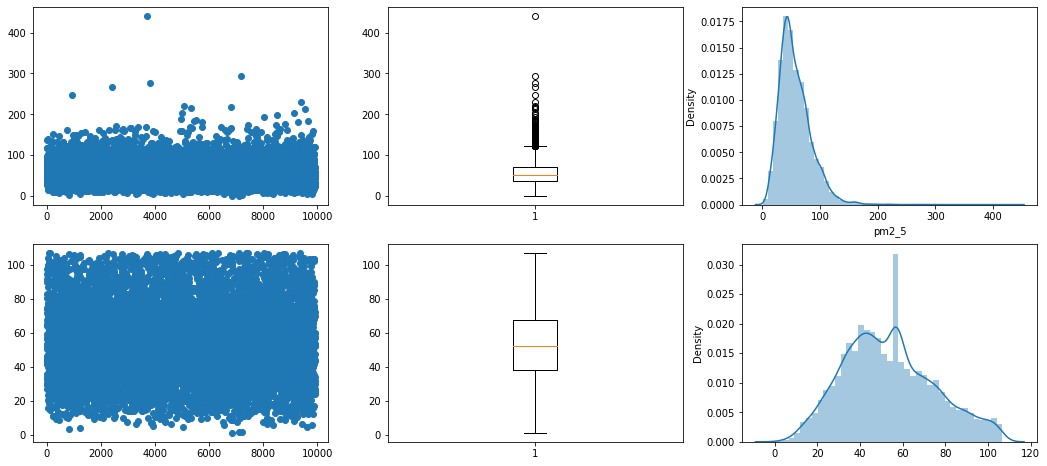

In [11]:
alpha = np.quantile(train_df.pm2_5,0.95)
mu = np.mean(train_df.pm2_5)
new = []
for i in train_df.pm2_5:
    if i>=alpha:
        new.append(mu)
    else:
        new.append(i)

plt.figure(figsize=(18,8))
plt.subplot(2,3,1)
plt.scatter(range(train_df.shape[0]),train_df.pm2_5)
plt.subplot(2,3,2)
plt.boxplot(train_df.pm2_5)
plt.subplot(2,3,3)
sns.distplot(train_df.pm2_5)
plt.subplot(2,3,4)
plt.scatter(range(len(new)),new)
plt.subplot(2,3,5)
plt.boxplot(new)
plt.subplot(2,3,6)
sns.distplot(new)

train_df.pm2_5=new

In [12]:
# device_dict=(df.device.value_counts()/df.shape[0]).to_dict()
# device_cot = [device_dict[i] for i in train_df.device]
# train_df.device=device_cot


In [13]:
train_df.head()

,device,humidity,temp_mean,UvAerosolIndex_absorbing_aerosol_index,UvAerosolIndex_solar_azimuth_angle,UvAerosolIndex_solar_zenith_angle,Ozone_cloud_fraction,Ozone_solar_azimuth_angle,Ozone_solar_zenith_angle,Cloud_cloud_fraction,Cloud_cloud_top_pressure,Cloud_cloud_top_height,Cloud_cloud_base_pressure,Cloud_cloud_base_height,Cloud_surface_albedo,pm2_5
0,ANQ16PZJ,0.846844,22.038542,-1.642264,-93.106096,19.208093,0.410418,-93.106096,19.208093,0.436799,61535.804688,4181.792969,69589.453125,3181.793457,0.278111,63.853333
1,AB6051M4,0.874493,21.545833,0.217813,-103.695694,36.372738,0.460678,-103.695694,36.372738,NaN,NaN,NaN,NaN,NaN,NaN,32.507083
2,A0WN66FH,0.729340,23.568655,0.691562,-127.856827,40.857887,0.656354,-127.856827,40.857887,0.657462,59516.625000,4440.391113,67341.109375,3440.390869,0.416631,80.290833
3,aq_41,0.919271,16.338542,-2.276711,-121.239726,19.201247,0.000000,-121.239726,19.201247,NaN,NaN,NaN,NaN,NaN,NaN,42.601687
4,aq_41,0.858365,16.602083,-2.355566,-57.277913,21.865928,0.090565,-57.277913,21.865928,0.092704,56771.306869,4842.057488,64347.788635,3842.057585,0.277157,89.642229


In [14]:
train_df.isna().sum()/df.shape[0]

device                                    0.000000
humidity                                  0.000000
temp_mean                                 0.002016
UvAerosolIndex_absorbing_aerosol_index    0.033760
UvAerosolIndex_solar_azimuth_angle        0.033760
UvAerosolIndex_solar_zenith_angle         0.033760
Ozone_cloud_fraction                      0.054016
Ozone_solar_azimuth_angle                 0.054016
Ozone_solar_zenith_angle                  0.054016
Cloud_cloud_fraction                      0.152071
Cloud_cloud_top_pressure                  0.152071
Cloud_cloud_top_height                    0.152071
Cloud_cloud_base_pressure                 0.152071
Cloud_cloud_base_height                   0.152071
Cloud_surface_albedo                      0.152071
pm2_5                                     0.000000
dtype: float64

In [15]:
train_df.fillna(0, inplace=True)

In [16]:
X=train_df.drop("pm2_5", axis=1)
y=train_df.pm2_5

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,make_union
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from lightgbm import LGBMRegressor


In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)

In [19]:
quanti_var=list(train_df.columns[train_df.dtypes=="float64"])
quanti_var.remove("pm2_5")
quali_var=list(train_df.columns[train_df.dtypes=="object"])
num_pipeline=make_pipeline(PolynomialFeatures(3), SelectKBest(f_regression, k=150),StandardScaler())
cat_pipeline=make_pipeline(OneHotEncoder(handle_unknown='ignore'))
transformer=make_column_transformer((num_pipeline,quanti_var),(cat_pipeline,quali_var))
# model=make_pipeline(transformer,MLPRegressor(random_state=48, max_iter=200))
model=make_pipeline(transformer,MLPRegressor(random_state=48, max_iter=200))

# 'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'
# LGBMRegressor(boosting_type='gbdt', objective='regression', num_leaves=1200,
#                                 learning_rate=0.17, n_estimators=380, max_depth=9,
#                                 metric='mae', bagging_fraction=0.8, feature_fraction=0.8, reg_lambda=0.9, use_missing=False)
model.fit(X_train,y_train)
model.score(X_test,y_test)

c:\Users\user\Anaconda3\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:289: RuntimeWarning: divide by zero encountered in true_divide
  correlation_coefficient /= X_norms
c:\Users\user\Anaconda3\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:358: RuntimeWarning: invalid value encountered in true_divide
  f_statistic = corr_coef_squared / (1 - corr_coef_squared) * deg_of_freedom
c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  ConvergenceWarning,


0.5456500465418359

In [20]:
y_pred=model.predict(X_test)
mean_absolute_error(y_test, y_pred)

11.326821357881911

## Submission

In [21]:
test_df = pd.read_csv("test.csv") 
submit = pd.read_csv("SampleSubmission.csv")

In [22]:
cols = [t for t in test_df.columns if t not in train_df.columns]
test_df = test_df.drop(cols, axis=1)
test_df.fillna(0,inplace=True)

In [23]:
most=train_df.device.value_counts().index[33]
device=[]
for i,j in enumerate(test_df.device):
    if j not in train_df.device.values:
        device.append(most)
    else:
        device.append(j)

test_df.device=device

# means=train_df.device.mean()
# device=[]
# for i,j in enumerate(test_df.device):
#     if j not in device_dict:
#         device.append(144)
#     else:
#         device.append(device_dict[j])

# test_df.device=device

In [24]:
test_df.head()

,device,humidity,temp_mean,UvAerosolIndex_absorbing_aerosol_index,UvAerosolIndex_solar_azimuth_angle,UvAerosolIndex_solar_zenith_angle,Ozone_cloud_fraction,Ozone_solar_azimuth_angle,Ozone_solar_zenith_angle,Cloud_cloud_fraction,Cloud_cloud_top_pressure,Cloud_cloud_top_height,Cloud_cloud_base_pressure,Cloud_cloud_base_height,Cloud_surface_albedo
0,aq_43,0.756840,23.849653,-2.512214,-101.600266,21.007084,0.060996,-101.600266,21.007084,0.035547,36716.141728,8325.718024,41969.524699,7325.718482,0.210430
1,aq_54,0.810854,22.075347,-0.535317,-125.937157,41.709011,0.450623,-125.937157,41.709011,0.449991,63086.023438,4060.879639,70871.984375,3060.879639,0.344436
2,aq_59,0.883253,20.050694,-1.253812,-120.660301,40.175678,0.371457,-120.660301,40.175678,0.362186,46783.820820,6456.160528,53084.224103,5456.160528,0.326882
3,AW66FF7V,0.782583,22.248958,-2.067666,-72.224289,20.675251,0.076712,-72.224289,20.675251,0.077843,45528.261719,6682.570801,51503.203125,5682.570801,0.212181
4,aq_45,0.770116,22.565217,-1.834848,-139.070473,32.048299,0.579272,-139.070473,32.048299,0.597243,65512.797785,3757.637022,73461.827324,2757.637022,0.262021


In [25]:
pred=model.predict(test_df)

In [26]:
submit.pm2_5=pred

In [27]:
# submit.to_csv("submit_16.csv", index=False)

In [28]:
# test = pd.read_csv("test.csv") 
# submission = pd.DataFrame(data=test["ID"], columns = ["ID"])
# submission["pm2_5"] = pred
# submission.to_csv("submission_27.csv",index=False)

In [29]:
# len([i for i in test.device if i not in train_df.device.values])